# Tarea 02 — Cuaderno de instructora

## Estimar y predecir olas estacionales con un modelo SIRS

En la clase 2 ajustamos un modelo con una tasa de transmisión constante, $\beta$. En este cuaderno construiremos un ejemplo sintético en el que la transmisión cambia de manera periódica a lo largo del año. Usaremos las dos primeras temporadas para estimar los parámetros y reservaremos la tercera para evaluar una predicción de la siguiente ola.

Este es el cuaderno completo de la instructora: conserva los parámetros verdaderos para verificar que el ejemplo funciona. En la versión para el alumnado se ocultarán esos valores y las curvas generadoras.

In [1]:
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'font.size': 12,
})

rng = np.random.default_rng(20261104)

## 1. Modelo SIRS con transmisión estacional

Un SIR cerrado no suele producir olas recurrentes grandes: después de un brote quedan pocos susceptibles. Para poder observar varias temporadas incorporamos pérdida de inmunidad, de modo que las personas recuperadas regresan al compartimento susceptible.

$$
\frac{dS}{dt}=-\beta(t)\frac{SI}{N}+\omega R,
\qquad
\frac{dI}{dt}=\beta(t)\frac{SI}{N}-\gamma I,
\qquad
\frac{dR}{dt}=\gamma I-\omega R.
$$

La tasa de transmisión cambia con un periodo conocido $T=52$ semanas:

$$
\beta(t;\theta)=
\exp\left[
\theta_0+
\theta_s\sin\left(\frac{2\pi t}{T}\right)+
\theta_c\cos\left(\frac{2\pi t}{T}\right)
\right].
$$

La exponencial garantiza que $\beta(t;\theta)>0$. Estimaremos sólo $\theta=(\theta_0,\theta_s,\theta_c)$; $N$, $\gamma$, $\omega$, $T$ y la condición inicial se consideran conocidos.

### Incidencia en un modelo SIRS

En el SIR de la clase 2 podíamos calcular la incidencia mediante la disminución de $S$. Aquí eso ya no funciona, porque $S(t)$ también aumenta por el flujo $R\to S$. Por eso añadimos un acumulador de infecciones, $C(t)$:

$$
\frac{dC}{dt}=\beta(t)\frac{S(t)I(t)}{N}.
$$

La incidencia semanal predicha será

$$
G_j(\theta)=C(t_j)-C(t_{j-1}).
$$

In [3]:
# La unidad de tiempo es una semana.
N = 100_000
T = 52.0
gamma = 1 / 2       # periodo infeccioso medio: 2 semanas
omega = 1 / 52      # duración media de la inmunidad: 1 año

n_total = 3 * int(T)
n_entrenamiento = 2 * int(T)

# En este ejemplo observamos una enfermedad que ya circulaba antes de t=0.
# Esta condición inicial evita que una primera ola transitoria domine el ejemplo.
I0 = 100.0
R0 = 49_900.0
S0 = N - I0 - R0
y0 = np.array([S0, I0, R0, 0.0])

theta_true = np.array([
    np.log(1.2),
    0.45,
    -0.25,
])

sigma_observacion = 350.0

In [4]:
def beta_estacional(t, theta):
    """Tasa de transmisión semanal, siempre positiva."""
    theta_0, theta_s, theta_c = theta
    fase = 2 * np.pi * np.asarray(t) / T
    return np.exp(theta_0 + theta_s * np.sin(fase) + theta_c * np.cos(fase))


def sirs_estacional(t, y, theta):
    """Lado derecho del modelo SIRS con acumulador de incidencia."""
    S, I, R, C = y
    beta_t = beta_estacional(t, theta)
    infecciones_nuevas = beta_t * S * I / N

    dS = -infecciones_nuevas + omega * R
    dI = infecciones_nuevas - gamma * I
    dR = gamma * I - omega * R
    dC = infecciones_nuevas
    return [dS, dI, dR, dC]


def resolver_sirs(theta, n_semanas, y_inicial=y0):
    """Resuelve el modelo y devuelve estados e incidencia semanal."""
    t_eval = np.arange(n_semanas + 1, dtype=float)
    solucion = solve_ivp(
        sirs_estacional,
        t_span=(0, n_semanas),
        y0=y_inicial,
        args=(theta,),
        t_eval=t_eval,
        method='LSODA',
        rtol=1e-8,
        atol=1e-6,
    )
    if not solucion.success:
        raise RuntimeError(solucion.message)

    S, I, R, C = solucion.y
    return {
        'semana': t_eval,
        'S': S,
        'I': I,
        'R': R,
        'C': C,
        'semana_incidencia': t_eval[1:],
        'incidencia': np.diff(C),
    }


def G(theta, n_semanas):
    """Operador directo: incidencia semanal predicha."""
    return resolver_sirs(theta, n_semanas)['incidencia']


def resumen_estacional(theta):
    """Resume nivel, amplitud y semana del máximo de beta(t)."""
    theta_0, theta_s, theta_c = theta
    amplitud_log = np.hypot(theta_s, theta_c)
    fase = np.arctan2(theta_c, theta_s)
    semana_maxima = ((np.pi / 2 - fase) * T / (2 * np.pi)) % T
    return {
        'nivel_basal_geometrico': np.exp(theta_0),
        'amplitud_log': amplitud_log,
        'beta_minima': np.exp(theta_0 - amplitud_log),
        'beta_maxima': np.exp(theta_0 + amplitud_log),
        'semana_maxima': semana_maxima,
    }

## 2. Generamos la epidemia estacional verdadera

Primero simulamos tres años con los parámetros verdaderos. Esta curva sólo está disponible en el cuaderno de instructora; el alumnado verá después únicamente los casos observados.

Nota: $\exp(\theta_0)$ es un nivel basal en escala logarítmica o media geométrica de $\beta(t)$, no su media aritmética.

In [5]:
verdad = resolver_sirs(theta_true, n_total)
incidencia_true = verdad['incidencia']
semanas_incidencia = verdad['semana_incidencia']

resumen_true = resumen_estacional(theta_true)
print(f"beta mínima: {resumen_true['beta_minima']:.3f} por semana")
print(f"beta máxima: {resumen_true['beta_maxima']:.3f} por semana")
print(f"Semana anual de máximo de beta: {resumen_true['semana_maxima']:.1f}")

for anio in range(3):
    inicio, fin = anio * int(T), (anio + 1) * int(T)
    incidencia_anual = incidencia_true[inicio:fin]
    semana_pico = inicio + 1 + np.argmax(incidencia_anual)
    print(
        f"Año {anio + 1}: {incidencia_anual.sum():.0f} infecciones, "
        f"pico en la semana {semana_pico}"
    )

beta mínima: 0.717 por semana
beta máxima: 2.008 por semana
Semana anual de máximo de beta: 17.2
Año 1: 64708 infecciones, pico en la semana 17
Año 2: 62002 infecciones, pico en la semana 73
Año 3: 59988 infecciones, pico en la semana 125


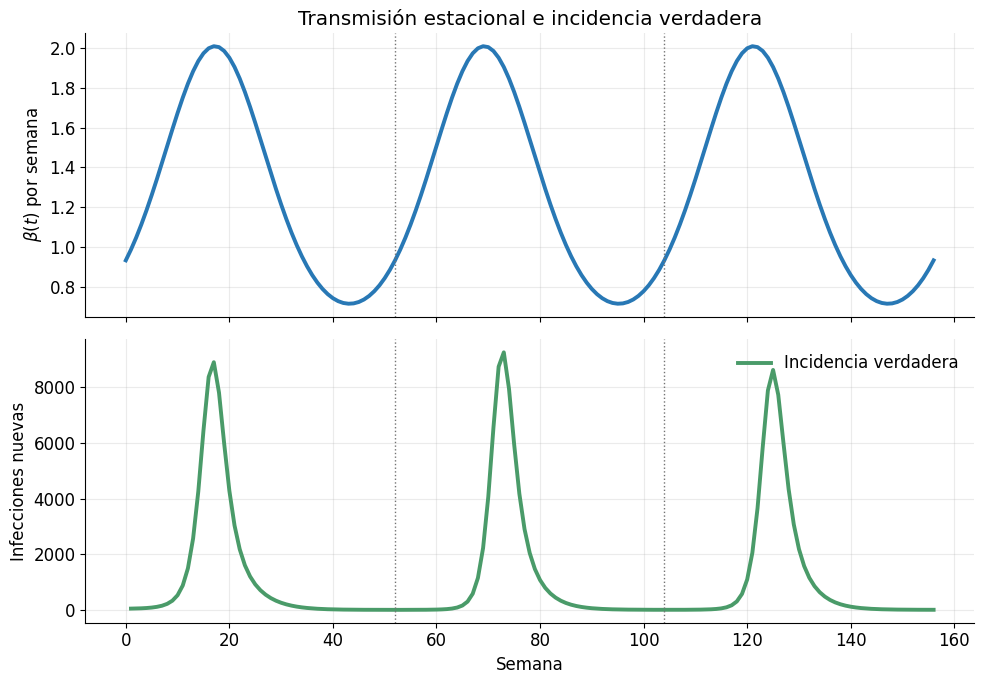

In [6]:
fig, (ax_beta, ax_inc) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax_beta.plot(verdad['semana'], beta_estacional(verdad['semana'], theta_true),
             color='#2878B5', lw=2.8)
ax_beta.set(ylabel=r'$\beta(t)$ por semana',
            title='Transmisión estacional e incidencia verdadera')

ax_inc.plot(semanas_incidencia, incidencia_true, color='#4A9B69', lw=2.8,
            label='Incidencia verdadera')
ax_inc.set(xlabel='Semana', ylabel='Infecciones nuevas')
ax_inc.legend(frameon=False, loc='best')

for ax in (ax_beta, ax_inc):
    for corte in (52, 104):
        ax.axvline(corte, color='0.45', ls=':', lw=1)

plt.tight_layout()
plt.show()

## 3. Construimos datos observados sintéticos

Usamos el mismo primer modelo de observación de la clase 2:

$$
Y_j=G_j(\theta_{\mathrm{true}})+\varepsilon_j,
\qquad
\varepsilon_j\overset{\mathrm{ind}}{\sim}
\mathcal{N}(0,\sigma^2).
$$

Después de añadir el error, reemplazamos los valores negativos por cero como una corrección práctica para no mostrar conteos negativos.

In [7]:
casos_observados = np.maximum(
    incidencia_true + rng.normal(0, sigma_observacion, size=incidencia_true.shape),
    0,
)

datos_para_tarea = pd.DataFrame({
    'semana': semanas_incidencia.astype(int),
    'casos_observados': casos_observados,
})

archivo_datos = Path('datos_tarea_02_sirs_estacional.csv')
datos_para_tarea.to_csv(archivo_datos, index=False)

print(f'Datos guardados en: {archivo_datos.resolve()}')
display(datos_para_tarea.head())

Datos guardados en: /Users/mdazatorres/Library/CloudStorage/GoogleDrive-mdazatorres@cimat.mx/My Drive/Cursillos/Modelos matemáticos de enfermedades infecciosas con Python/dia_01/datos_tarea_02_sirs_estacional.csv


,semana,casos_observados
0,1,342.358858
1,2,587.590728
2,3,0.000000
3,4,0.000000
4,5,0.000000


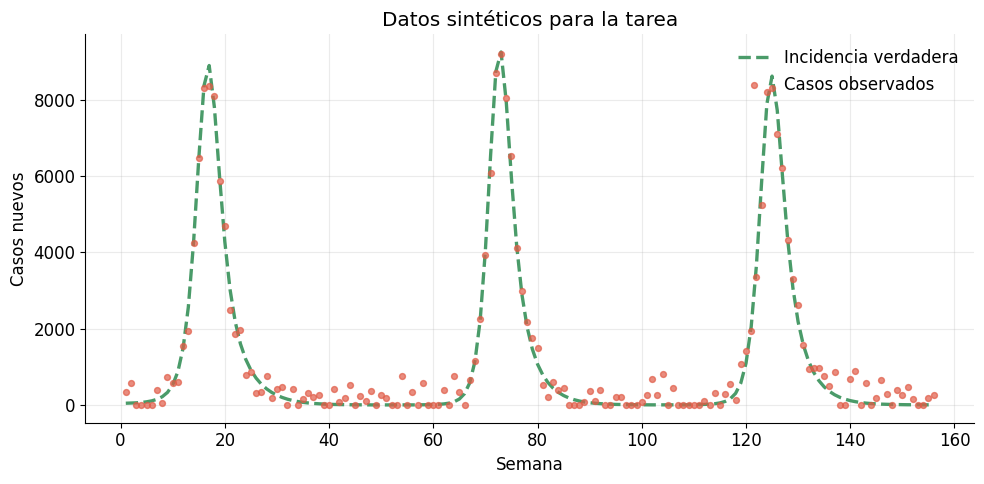

In [8]:
fig, ax = plt.subplots()
ax.plot(semanas_incidencia, incidencia_true, color='#4A9B69', ls='--', lw=2.4,
        label='Incidencia verdadera')
ax.scatter(semanas_incidencia, casos_observados, color='#E05C47', s=18, alpha=0.7,
           label='Casos observados', zorder=3)
ax.set(xlabel='Semana', ylabel='Casos nuevos',
       title='Datos sintéticos para la tarea')
ax.legend(frameon=False, loc='best')
plt.tight_layout()
plt.show()

## 4. Entrenamiento y prueba

Usaremos las primeras dos temporadas, semanas $1,\ldots,104$, para estimar $\theta$. La tercera temporada, semanas $105,\ldots,156$, queda completamente retenida para probar si el patrón estacional estimado anticipa la siguiente ola.

Es importante conservar el mismo reloj de calendario al predecir: no reiniciamos $t$ en la semana 105, porque la fase de la estacionalidad depende de $t\bmod T$.

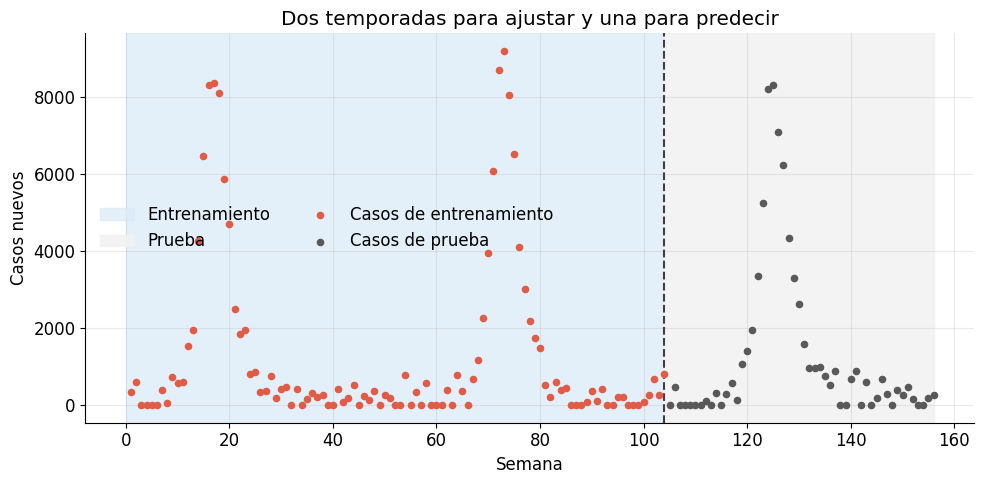

In [9]:
mask_train = np.arange(n_total) < n_entrenamiento

fig, ax = plt.subplots()
ax.axvspan(0, n_entrenamiento, color='#D9EAF7', alpha=0.7, label='Entrenamiento')
ax.axvspan(n_entrenamiento, n_total, color='#F2F2F2', alpha=0.9, label='Prueba')
ax.scatter(semanas_incidencia[mask_train], casos_observados[mask_train],
           color='#E05C47', s=20, label='Casos de entrenamiento', zorder=3)
ax.scatter(semanas_incidencia[~mask_train], casos_observados[~mask_train],
           color='0.35', s=20, label='Casos de prueba', zorder=3)
ax.axvline(n_entrenamiento, color='0.25', ls='--', zorder=2)
ax.set(xlabel='Semana', ylabel='Casos nuevos',
       title='Dos temporadas para ajustar y una para predecir')
ax.legend(frameon=False, loc='best', ncol=2)
plt.tight_layout()
plt.show()

## 5. Ajuste por mínimos cuadrados

Para cada vector $\theta$, el operador directo $G(\theta)$ resuelve el modelo y devuelve la incidencia semanal. Elegimos los parámetros que minimizan la discrepancia en el periodo de entrenamiento:

$$
Q_{\mathrm{ent}}(\theta)
=
\sum_{j=1}^{104}
\left[Y_j-G_j(\theta)\right]^2,
$$

$$
\widehat\theta
=
\underset{\theta}{\operatorname*{argmin}}
\;Q_{\mathrm{ent}}(\theta).
$$

Ahora hay tres parámetros, por lo que usamos `minimize` en lugar de `minimize_scalar`.

In [10]:
def perdida(theta, observaciones, n_entrenamiento):
    prediccion = G(theta, n_entrenamiento)
    residuos = observaciones[:n_entrenamiento] - prediccion
    return np.sum(residuos ** 2)


cotas = [
    (np.log(0.7), np.log(1.6)),
    (-0.75, 0.75),
    (-0.75, 0.75),
]

ajuste = minimize(
    perdida,
    x0=np.zeros(3),
    args=(casos_observados, n_entrenamiento),
    method='L-BFGS-B',
    bounds=cotas,
    options={'maxiter': 500},
)

if not ajuste.success:
    raise RuntimeError(ajuste.message)

theta_estimado = ajuste.x
modelo_ajustado = resolver_sirs(theta_estimado, n_total)
incidencia_ajustada = modelo_ajustado['incidencia']

print(f'Optimización terminada: {ajuste.message}')
print(f'Valor de la función objetivo: {ajuste.fun:,.0f}')

Optimización terminada: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Valor de la función objetivo: 7,984,071


In [11]:
tabla_parametros = pd.DataFrame({
    'parámetro': [r'$\theta_0$', r'$\theta_s$', r'$\theta_c$'],
    'verdadero': theta_true,
    'estimado': theta_estimado,
})
tabla_parametros['error'] = tabla_parametros['estimado'] - tabla_parametros['verdadero']
display(tabla_parametros.style.format({'verdadero': '{:.4f}', 'estimado': '{:.4f}', 'error': '{:+.4f}'}))

resumen_estimado = resumen_estacional(theta_estimado)
print(f"Semana estimada de máximo de beta: {resumen_estimado['semana_maxima']:.1f}")
print(f"Rango estimado de beta: ({resumen_estimado['beta_minima']:.3f}, "
      f"{resumen_estimado['beta_maxima']:.3f}) por semana")

,parámetro,verdadero,estimado,error
0,$\theta_0$,0.1823,0.1740,-0.0083
1,$\theta_s$,0.4500,0.4559,+0.0059
2,$\theta_c$,-0.2500,-0.2468,+0.0032


Semana estimada de máximo de beta: 17.1
Rango estimado de beta: (0.709, 1.999) por semana


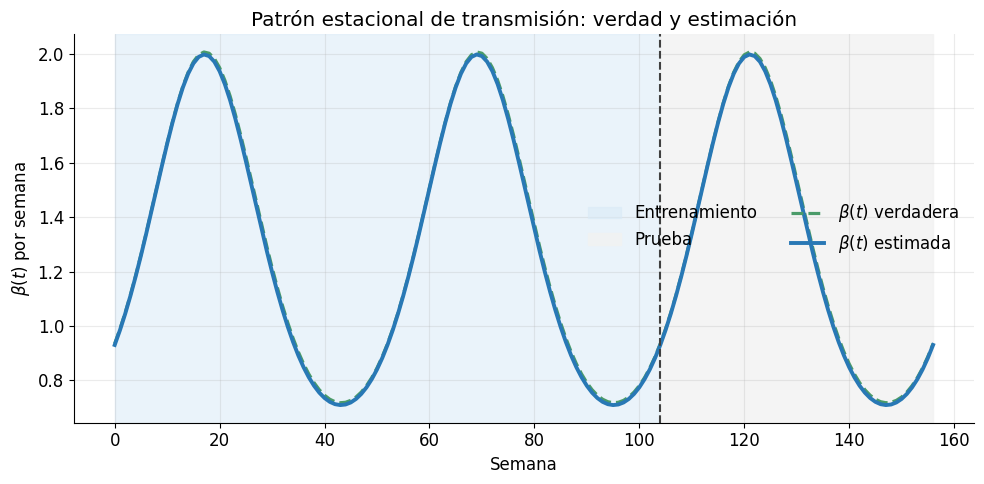

In [12]:
fig, ax = plt.subplots()
ax.axvspan(0, n_entrenamiento, color='#D9EAF7', alpha=0.55, label='Entrenamiento')
ax.axvspan(n_entrenamiento, n_total, color='#F2F2F2', alpha=0.8, label='Prueba')
ax.plot(verdad['semana'], beta_estacional(verdad['semana'], theta_true),
        color='#4A9B69', ls='--', lw=2.3, label=r'$\beta(t)$ verdadera')
ax.plot(verdad['semana'], beta_estacional(verdad['semana'], theta_estimado),
        color='#2878B5', lw=2.8, label=r'$\beta(t)$ estimada')
ax.axvline(n_entrenamiento, color='0.25', ls='--')
ax.set(xlabel='Semana', ylabel=r'$\beta(t)$ por semana',
       title='Patrón estacional de transmisión: verdad y estimación')
ax.legend(frameon=False, loc='best', ncol=2)
plt.tight_layout()
plt.show()

## 6. Predicción de la tercera temporada

La curva azul se obtuvo ajustando únicamente las primeras 104 semanas. Al continuar la simulación hasta la semana 156, el modelo pronostica la tercera ola sin haber visto sus observaciones. La línea verde punteada aparece sólo para verificar el ejemplo sintético.

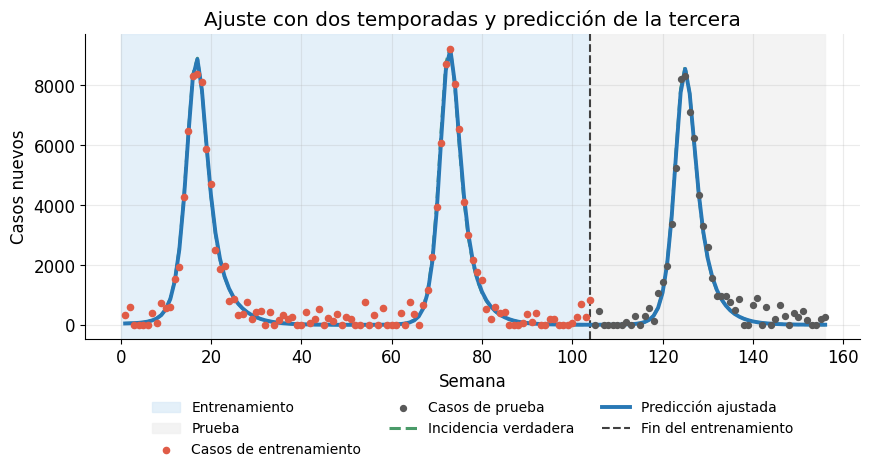

In [13]:
fig, ax = plt.subplots()
ax.axvspan(0, n_entrenamiento, color='#D9EAF7', alpha=0.7, label='Entrenamiento')
ax.axvspan(n_entrenamiento, n_total, color='#F2F2F2', alpha=0.9, label='Prueba')
ax.scatter(semanas_incidencia[mask_train], casos_observados[mask_train],
           color='#E05C47', s=20, label='Casos de entrenamiento', zorder=4)
ax.scatter(semanas_incidencia[~mask_train], casos_observados[~mask_train],
           color='0.35', s=18, label='Casos de prueba', zorder=4)
ax.plot(semanas_incidencia, incidencia_true, color='#4A9B69', ls='--', lw=2.2,
        label='Incidencia verdadera', zorder=2)
ax.plot(semanas_incidencia, incidencia_ajustada, color='#2878B5', lw=2.8,
        label='Predicción ajustada', zorder=3)
ax.axvline(n_entrenamiento, color='0.25', ls='--', label='Fin del entrenamiento')
ax.set(xlabel='Semana', ylabel='Casos nuevos',
       title='Ajuste con dos temporadas y predicción de la tercera')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16),
          ncol=3, fontsize=10)
fig.subplots_adjust(bottom=0.27)
plt.show()

In [14]:
rmse_entrenamiento = np.sqrt(np.mean(
    (casos_observados[:n_entrenamiento] - incidencia_ajustada[:n_entrenamiento]) ** 2
))
rmse_prueba = np.sqrt(np.mean(
    (casos_observados[n_entrenamiento:] - incidencia_ajustada[n_entrenamiento:]) ** 2
))

print(f'RMSE en entrenamiento: {rmse_entrenamiento:.1f} casos por semana')
print(f'RMSE en prueba:        {rmse_prueba:.1f} casos por semana')

RMSE en entrenamiento: 277.1 casos por semana
RMSE en prueba:        312.0 casos por semana


## Para la versión de tarea

La versión para el alumnado puede conservar las funciones del modelo y los datos `datos_tarea_02_sirs_estacional.csv`, pero debe ocultar $\theta_{\mathrm{true}}$, la incidencia verdadera y las comparaciones con la verdad. Las preguntas centrales podrían ser:

1. ¿Por qué en SIRS no podemos usar $S(t_{j-1})-S(t_j)$ como incidencia?
2. Implementa $\beta(t;\theta)$ y explica por qué usamos una exponencial.
3. Ajusta $\theta_0$, $\theta_s$ y $\theta_c$ con las primeras dos temporadas.
4. ¿En qué semana del año es máxima la transmisión estimada?
5. Predice la tercera temporada y calcula el RMSE de prueba.
6. ¿Qué supuesto permite usar las dos primeras temporadas para pronosticar la tercera?

Una extensión opcional es comparar este modelo contra uno sin estacionalidad, imponiendo $\theta_s=\theta_c=0$.